# Course mail: aishohan001@gmail.com

In [ ]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [ ]:
scoreArry = data["score"].to_numpy()
attendanceArray = data["attendance"].to_numpy()
print(f"Score Array: {scoreArry}")
print(f"Attendance Array: {attendanceArray}")

#for score arry
print(scoreArry.dtype)
print(scoreArry.ndim)
print(scoreArry.shape)
print(scoreArry.size)

#for attendace array
print(attendanceArray.dtype)
print(attendanceArray.ndim)
print(attendanceArray.shape)
print(attendanceArray.size)


Score Array: [76 90 46 60 48 78 57 43 64 99 53 89 97 48 65 92 41 59 67 86 99 46 83 47
 86 74 53 56 75 89 79 43 41 45 93 81 43 93 68 57 65 83 73 49 75 53 70 87
 54 47]
Attendance Array: [73 82 99 80 75 77 83 85 84 88 74 60 84 66 68 83 60 67 83 70 76 67 94 94
 92 64 98 87 66 68 67 71 93 92 82 83 96 94 99 81 86 94 60 94 96 73 62 60
 64 85]
int64
1
(50,)
50
int64
1
(50,)
50


# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

# Write Answer 02:


In [ ]:
from numpy._core import minimum
scoreArray = data["score"].to_numpy()
attendanceArray = data["attendance"].to_numpy()

minimum_score = np.min(scoreArray)
maximum_score = np.max(scoreArray)

avarage_score = np.mean(scoreArray)

avarage_attendance = np.mean(attendanceArray)

filter_score_array = scoreArray[scoreArray > avarage_score]


# print all the result that i get
print(minimum_score)
print(maximum_score)
print(avarage_score)
print(avarage_attendance)
print(filter_score_array)



41
99
67.3
79.58
[76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [ ]:
df = pd.read_csv('school_data.csv')
first_three_row = df.head(3)
print(first_three_row)
print(df.info())
print(df.describe())

filter_dataset = df[["student_id", "student_age", "department", "grade"]]
print(filter_dataset)

student_age_between_16_to_20 = filter_dataset[filter_dataset["student_age"].between(16,20)]
print(student_age_between_16_to_20)

sort_age_bet_16_to_20 = student_age_between_16_to_20.sort_values(by="student_id")
print(sort_age_bet_16_to_20)

last_three_row = sort_age_bet_16_to_20.tail(3)
print(last_three_row)


   student_id  student_age  score  attendance department grade
0         201           21     76          73    Physics     B
1         202           18     90          82    Physics     A
2         203           19     46          99    Biology     F
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   50 non-null     int64 
 1   student_age  50 non-null     int64 
 2   score        50 non-null     int64 
 3   attendance   50 non-null     int64 
 4   department   50 non-null     object
 5   grade        50 non-null     object
dtypes: int64(4), object(2)
memory usage: 2.5+ KB
None
       student_id  student_age      score  attendance
count    50.00000    50.000000  50.000000   50.000000
mean    225.50000    18.280000  67.300000   79.580000
std      14.57738     1.852081  18.248008   12.163998
min     201.00000    15.000000  41.000000   60.


# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [ ]:
df["previous_score"] = df["score"]

special_departments = ["Computer Science", "Mathematics"]
condition = df["department"].isin(special_departments)

df.loc[condition, "score"] *= 1.10

df.loc[~condition, "score"] *= 1.05

df.loc[df["score"] > 100, "score"] = 100

df["score_increase"] = df["score"] - df["previous_score"]

df.rename(columns={"score": "new_score"}, inplace=True)

#data frame print
print(df[[
    "student_id",
    "department",
    "previous_score",
    "new_score",
    "score_increase"
]])

    student_id        department  previous_score  new_score  score_increase
0          201           Physics              76      79.80            3.80
1          202           Physics              90      94.50            4.50
2          203           Biology              46      48.30            2.30
3          204         Economics              60      63.00            3.00
4          205         Economics              48      50.40            2.40
5          206              Arts              78      81.90            3.90
6          207           Physics              57      59.85            2.85
7          208           Science              43      45.15            2.15
8          209  Computer Science              64      70.40            6.40
9          210  Computer Science              99     100.00            1.00
10         211       Mathematics              53      58.30            5.30
11         212           Physics              89      93.45            4.45
12         2

/tmp/ipykernel_878/1490425955.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ 70.4 108.9  58.3  52.8 108.9  91.3  47.3  74.8  77. ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[condition, "score"] *= 1.10


## Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

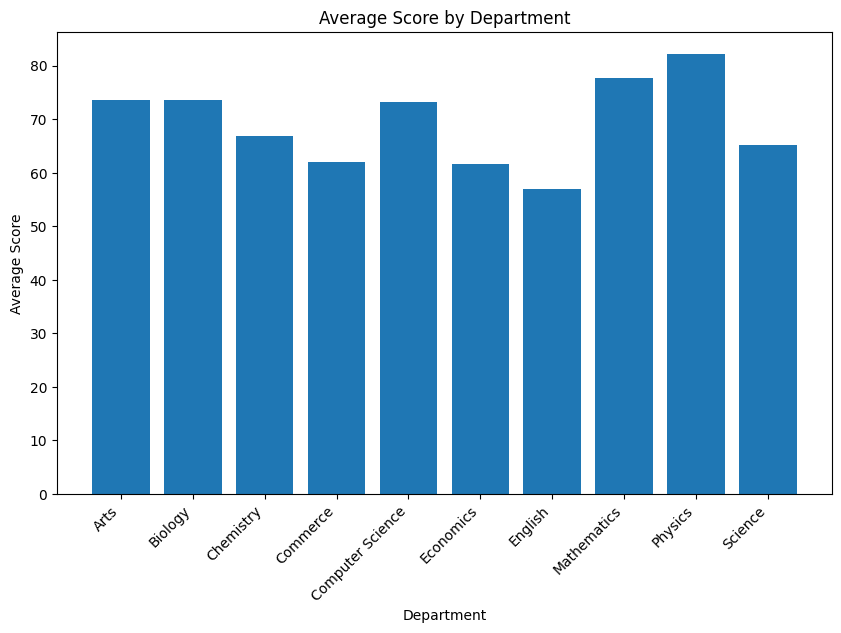

In [ ]:

average_score = df.groupby("department")["new_score"].mean()

plt.figure(figsize=(10, 6))

plt.bar(average_score.index, average_score.values)

plt.title("Average Score by Department")
plt.xlabel("Department")
plt.ylabel("Average Score")

plt.xticks(rotation=45, ha="right") # i use this for adjust the x-axis departmen name

plt.show()


# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

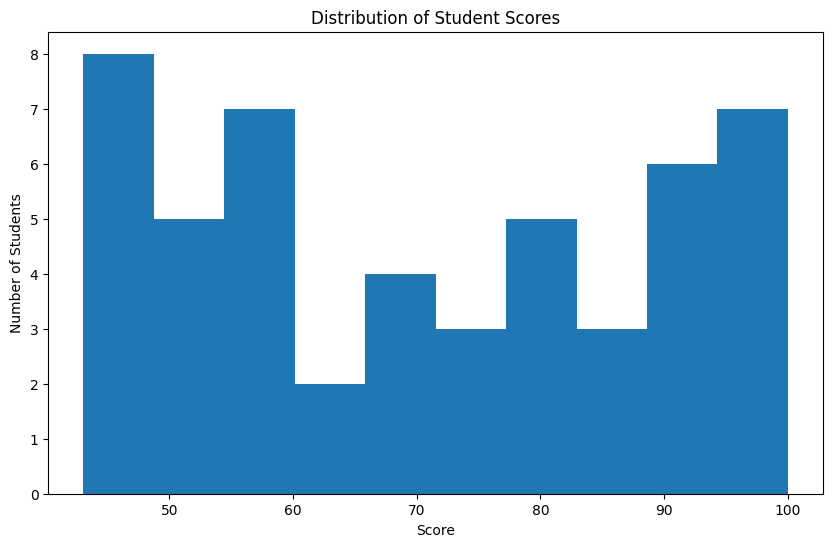

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(df["new_score"], bins=10)

plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")

plt.show()


# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


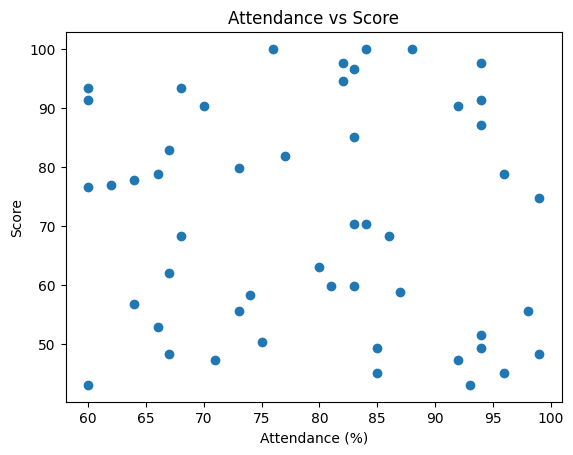

In [ ]:

# df

plt.scatter(df["attendance"], df["new_score"])


plt.title("Attendance vs Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")

plt.show()


# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

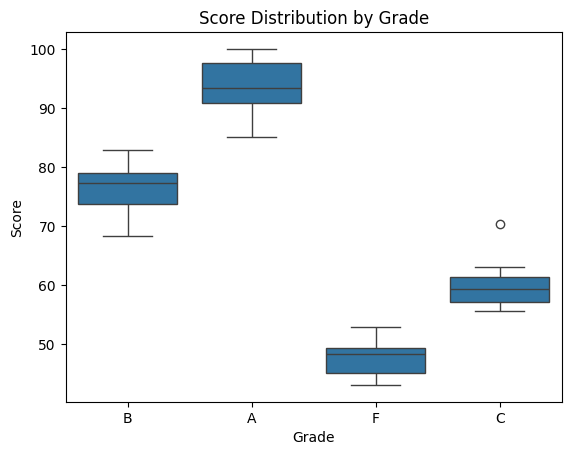

In [ ]:
sns.boxplot(data=df, x="grade", y="new_score")

plt.title("Score Distribution by Grade")
plt.xlabel("Grade")
plt.ylabel("Score")

plt.show()

# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

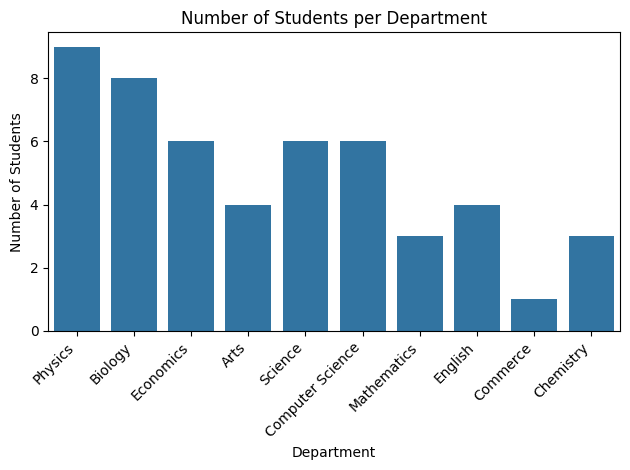

In [ ]:
sns.countplot(data=df, x="department")

plt.title("Number of Students per Department")
plt.xlabel("Department")
plt.ylabel("Number of Students")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

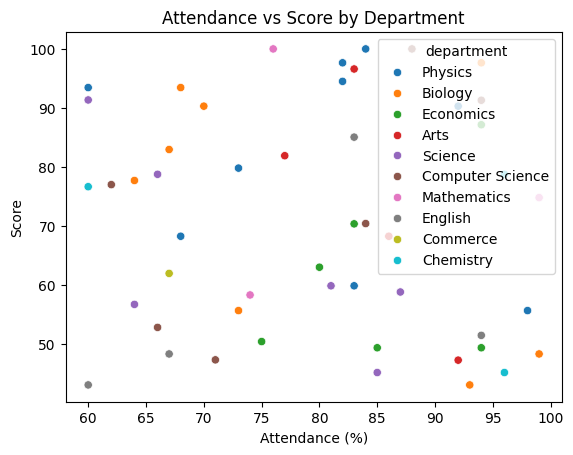

In [ ]:
sns.scatterplot(
    data=df,
    x="attendance",
    y="new_score",
    hue="department"
)

plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")

plt.show()